In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import missingno as msno
import data_preprocessing

from scipy.stats import linregress

sns.set_theme(style="white", context="notebook")
pd.set_option('display.max_columns', None)

# Découverte des données

La régularité TGV tient compte des différentes durées de trajet des clients (aussi appelée composite).

- Un train est considéré à l'heure si son retard au terminus est inférieur à 5min pour un parcours inférieur à 1h30
- Un train est considéré à l'heure si son retard au terminus est inférieur à 10min pour un parcours entre 1h30 et 3h
- Un train est considéré à l'heure si son retard au terminus est inférieur à 15min pour un parcours au-delà de 3h

Les horaires d'arrivée sont également déterminés par des capteurs détectant le passage du train à un point déterminé marquant l'entrée en gare et exceptionnellement par des suivis manuel. La précision des mesures est la minute arrondie à minute inférieure, ce qui est conforme à l'ensemble des normes retenues pour la confection des horaires et chronogrammes de service.


Le résultat de régularité global n’est ni la moyenne des résultats des 6 axes, ni la moyenne des résultats de l’ensemble des liaisons. En effet, le taux de régularité est le nombre de trains à l’heure à leur terminus sur le nombre de trains total ayant circulé sur le périmètre considéré. De plus, un même TGV peut compter dans plusieurs liaisons, mais il ne compte qu’une seule fois dans la régularité globale. Les chiffres de ce jeu de données ne doivent donc pas être utilisés pour calculer une régularité globale TGV ou par axe.

- Liaison = Une ligne du tableau (un segment mensuel entre une gare de départ et une gare d'arrivée).

- Mission = Le parcours complet réalisé par un train de bout en bout.

**NB :** Le Retard moyen trains en retard > 15 (si liaison concurrencée par vol) est censé correspondre à la moyenne du retard des trains ayant eu plus de 15 minutes de retard, sur les liaisons qui font face à la concurrence directe de l'avion. Sauf que certaines liaisons affichent des valeurs < 15 dans cette colonne. Bizarre ignorons-la.

In [2]:
df = pd.read_csv("../data/regularite-mensuelle-tgv-aqst.csv", sep=";")
df.head(5)

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Commentaire retards au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Commentaire retards à l'arrivée,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,3.693179,NaN,147,28.436735,6.511118,NaN,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,4.567119,NaN,105,18.049048,5.363539,"Ce mois-ci, l'OD a été touchée par les inciden...",32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,0.286283,NaN,19,24.736842,2.938053,NaN,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211,0.734290,NaN,58,33.726437,5.292211,NaN,39,5.292211,18,8,33.333333,22.222222,16.666667,20.370370,5.555556,1.851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784673,3.229701,NaN,89,14.592697,4.882372,NaN,42,4.882372,10,0,15.789474,45.614035,19.298246,15.789474,1.754386,1.754386


On ordonne et classe les colonnes entre elles pour faciliter la lisibilité de nos données

In [3]:
tuples_colonnes = [
    # Contexte et Identification de la Liaison
    ("Contexte", "Date"),
    ("Contexte", "Service"),
    ("Contexte", "Gare de départ"),
    ("Contexte", "Gare d'arrivée"),
    ("Contexte", "Durée moyenne du trajet"),
    
    # Volumes et Annulations
    ("Volumes & Annulations", "Nombre de circulations prévues"),
    ("Volumes & Annulations", "Nombre de trains annulés"),
    ("Volumes & Annulations", "Commentaire annulations"),
    
    # Départ (retard)
    ("Départ (retard)", "Nombre de trains en retard au départ"),
    ("Départ (retard)", "Retard moyen des trains en retard au départ"),
    ("Départ (retard)", "Retard moyen de tous les trains au départ"),
    ("Départ (retard)", "Commentaire retards au départ"),
    
    # Arrivée (retard)
    ("Arrivée (retard)", "Nombre de trains en retard à l'arrivée"),
    ("Arrivée (retard)", "Retard moyen des trains en retard à l'arrivée"),
    ("Arrivée (retard)", "Retard moyen de tous les trains à l'arrivée"),
    ("Arrivée (retard)", "Commentaire retards à l'arrivée"),
    ("Arrivée (retard)", "Nombre trains en retard > 15min"),
    ("Arrivée (retard)", "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)"),
    ("Arrivée (retard)", "Nombre trains en retard > 30min"),
    ("Arrivée (retard)", "Nombre trains en retard > 60min"),
    
    # Causes en % (Retard) 
    ("Causes en % (Retard)", "Prct retard pour causes externes"),
    ("Causes en % (Retard)", "Prct retard pour cause infrastructure"),
    ("Causes en % (Retard)", "Prct retard pour cause gestion trafic"),
    ("Causes en % (Retard)", "Prct retard pour cause matériel roulant"),
    ("Causes en % (Retard)", "Prct retard pour cause gestion en gare et réutilisation de matériel"),
    ("Causes en % (Retard)", "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)")
]

df.columns = pd.MultiIndex.from_tuples(tuples_colonnes)

In [4]:
df.head(5)

Contexte                                                    \
      Date   Service      Gare de départ      Gare d'arrivée   
0  2018-01  National    BORDEAUX ST JEAN  PARIS MONTPARNASSE   
1  2018-01  National             LE MANS  PARIS MONTPARNASSE   
2  2018-01  National  PARIS MONTPARNASSE   LA ROCHELLE VILLE   
3  2018-01  National  PARIS MONTPARNASSE              NANTES   
4  2018-01  National            POITIERS  PARIS MONTPARNASSE   

                                   Volumes & Annulations  \
  Durée moyenne du trajet Nombre de circulations prévues   
0                     141                            870   
1                      56                            406   
2                     166                            226   
3                     124                            508   
4                      94                            472   

                                                    \
  Nombre de trains annulés Commentaire annulations   
0                        5                     NaN   
1                        1                     NaN   
2                        0                     NaN   
3                        3                     NaN   
4                        4                     NaN   

                       Départ (retard)  \
  Nombre de trains en retard au départ   
0                                  289   
1                                  213   
2                                   21   
3                                   71   
4                                  224   

                                               \
  Retard moyen des trains en retard au départ   
0                                   11.247809   
1                                    8.479969   
2                                    6.239683   
3                                    7.235211   
4                                    6.784673   

                                                                           \
  Retard moyen de tous les trains au départ Commentaire retards au départ   
0                                  3.693179                           NaN   
1                                  4.567119                           NaN   
2                                  0.286283                           NaN   
3                                  0.734290                           NaN   
4                                  3.229701                           NaN   

                        Arrivée (retard)  \
  Nombre de trains en retard à l'arrivée   
0                                    147   
1                                    105   
2                                     19   
3                                     58   
4                                     89   

                                                 \
  Retard moyen des trains en retard à l'arrivée   
0                                     28.436735   
1                                     18.049048   
2                                     24.736842   
3                                     33.726437   
4                                     14.592697   

                                               \
  Retard moyen de tous les trains à l'arrivée   
0                                    6.511118   
1                                    5.363539   
2                                    2.938053   
3                                    5.292211   
4                                    4.882372   

                                                      \
                     Commentaire retards à l'arrivée   
0                                                NaN   
1  Ce mois-ci, l'OD a été touchée par les inciden...   
2                                                NaN   
3                                                NaN   
4                                                NaN   

                                   \
  Nombre trains en retard > 15min   
0                             110   
1                              32   
2                     

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12544 entries, 0 to 12543
Data columns (total 26 columns):
 #   Column                                                                                                               Non-Null Count  Dtype  
---  ------                                                                                                               --------------  -----  
 0   (Contexte, Date)                                                                                                     12544 non-null  str    
 1   (Contexte, Service)                                                                                                  12544 non-null  str    
 2   (Contexte, Gare de départ)                                                                                           12544 non-null  str    
 3   (Contexte, Gare d'arrivée)                                                                                           12544 non-null  str    
 4   (Contexte, Durée moye

On choisit des types plus adaptés pour nos colonnes si nécessaire :

In [6]:
# Conversion de la date
df[("Contexte", "Date")] = pd.to_datetime(df[("Contexte", "Date")], format='%Y-%m').dt.to_period('M')
# Conversion des types catégoriels
df[("Contexte", "Service")] = df[("Contexte", "Service")].astype('category')
df[("Contexte", "Gare de départ")] = df[("Contexte", "Gare de départ")].astype('category')
df[("Contexte", "Gare d'arrivée")] = df[("Contexte", "Gare d'arrivée")].astype('category')

In [7]:
df.head()

Contexte                                                    \
      Date   Service      Gare de départ      Gare d'arrivée   
0  2018-01  National    BORDEAUX ST JEAN  PARIS MONTPARNASSE   
1  2018-01  National             LE MANS  PARIS MONTPARNASSE   
2  2018-01  National  PARIS MONTPARNASSE   LA ROCHELLE VILLE   
3  2018-01  National  PARIS MONTPARNASSE              NANTES   
4  2018-01  National            POITIERS  PARIS MONTPARNASSE   

                                   Volumes & Annulations  \
  Durée moyenne du trajet Nombre de circulations prévues   
0                     141                            870   
1                      56                            406   
2                     166                            226   
3                     124                            508   
4                      94                            472   

                                                    \
  Nombre de trains annulés Commentaire annulations   
0                        5                     NaN   
1                        1                     NaN   
2                        0                     NaN   
3                        3                     NaN   
4                        4                     NaN   

                       Départ (retard)  \
  Nombre de trains en retard au départ   
0                                  289   
1                                  213   
2                                   21   
3                                   71   
4                                  224   

                                               \
  Retard moyen des trains en retard au départ   
0                                   11.247809   
1                                    8.479969   
2                                    6.239683   
3                                    7.235211   
4                                    6.784673   

                                                                           \
  Retard moyen de tous les trains au départ Commentaire retards au départ   
0                                  3.693179                           NaN   
1                                  4.567119                           NaN   
2                                  0.286283                           NaN   
3                                  0.734290                           NaN   
4                                  3.229701                           NaN   

                        Arrivée (retard)  \
  Nombre de trains en retard à l'arrivée   
0                                    147   
1                                    105   
2                                     19   
3                                     58   
4                                     89   

                                                 \
  Retard moyen des trains en retard à l'arrivée   
0                                     28.436735   
1                                     18.049048   
2                                     24.736842   
3                                     33.726437   
4                                     14.592697   

                                               \
  Retard moyen de tous les trains à l'arrivée   
0                                    6.511118   
1                                    5.363539   
2                                    2.938053   
3                                    5.292211   
4                                    4.882372   

                                                      \
                     Commentaire retards à l'arrivée   
0                                                NaN   
1  Ce mois-ci, l'OD a été touchée par les inciden...   
2                                                NaN   
3                                                NaN   
4                                                NaN   

                                   \
  Nombre trains en retard > 15min   
0                             110   
1                              32   
2                     

On compte 12544 lignes et 26 colonnes dans notre tableau de données.

Contexte               Date                                                                                               0
                       Service                                                                                            0
                       Gare de départ                                                                                     0
                       Gare d'arrivée                                                                                     0
                       Durée moyenne du trajet                                                                            0
Volumes & Annulations  Nombre de circulations prévues                                                                     0
                       Nombre de trains annulés                                                                           0
                       Commentaire annulations                                                                        12544
Départ (

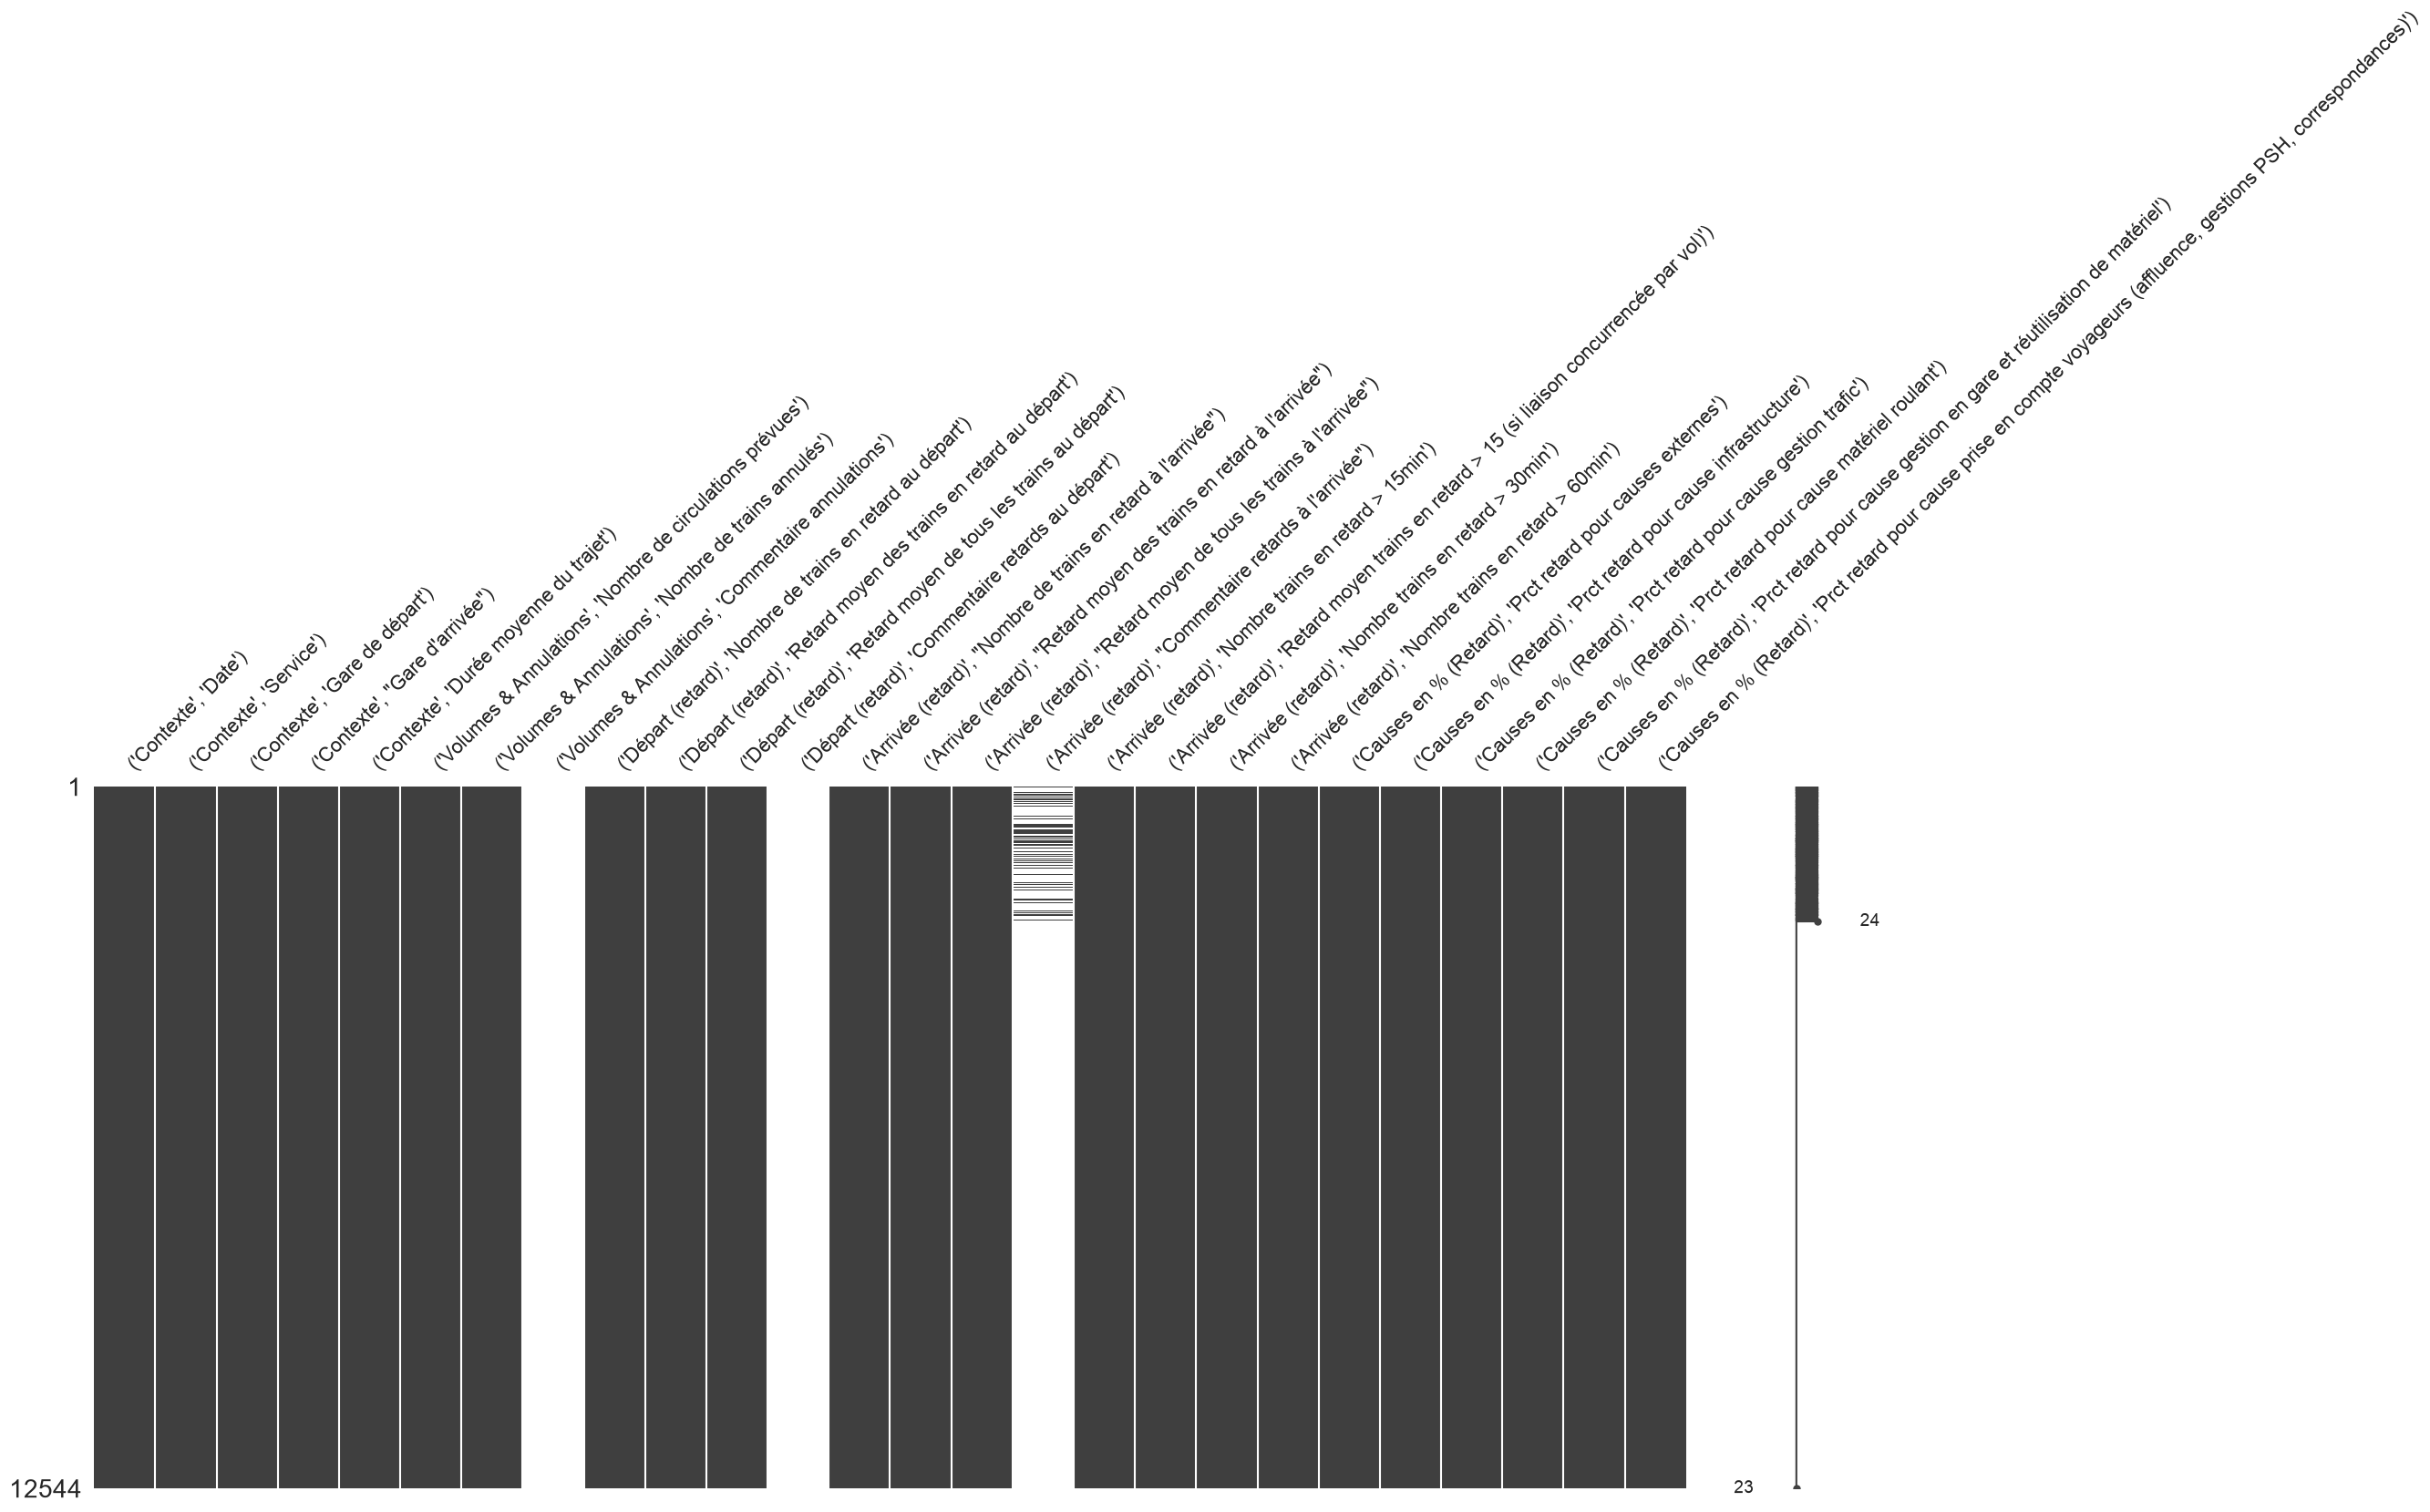

In [8]:
msno.matrix(df)
df.isna().sum()

On constate grâce aux infos globales de nos données que la colonne :

- "Commentaire annulations" ne contient que des valeurs vides (NaN) sur l'ensemble des $12\,544$ lignes.
- "Commentaire retards au départ" ne contient que des valeurs vides (NaN) sur l'ensemble des $12\,544$ lignes.

Aussi ces deux colonnes sont donc totalement inutiles pour notre analyse, car elles ne contiennent aucune donnée exploitable.

En revanche, la colonne "Commentaire retards à l'arrivée" contient des informations pour certaines lignes (698 valeurs renseignées). Elle peut être intéressante si on souhaite analyser qualitativement les causes de perturbations.

In [9]:
df = df.drop(columns=[("Volumes & Annulations", "Commentaire annulations"), 
                      ("Départ (retard)", "Commentaire retards au départ"), 
                      ("Arrivée (retard)", "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)")])

In [10]:
df.describe(include='all')

Contexte                                          \
           Date   Service Gare de départ Gare d'arrivée   
count     12544     12544          12544          12544   
unique      102         2             59             59   
top     2025-07  National     PARIS LYON     PARIS LYON   
freq        135     11012           2560           2560   
mean        NaN       NaN            NaN            NaN   
std         NaN       NaN            NaN            NaN   
min         NaN       NaN            NaN            NaN   
25%         NaN       NaN            NaN            NaN   
50%         NaN       NaN            NaN            NaN   
75%         NaN       NaN            NaN            NaN   
max         NaN       NaN            NaN            NaN   

                                        Volumes & Annulations  \
       Durée moyenne du trajet Nombre de circulations prévues   
count             12544.000000                   12544.000000   
unique                     NaN                            NaN   
top                        NaN                            NaN   
freq                       NaN                            NaN   
mean                170.628508                     272.623884   
std                  87.730733                     183.559230   
min                   0.000000                       0.000000   
25%                  99.000000                     151.000000   
50%                 163.000000                     230.000000   
75%                 223.000000                     362.000000   
max                 786.000000                    1100.000000   

                                                     Départ (retard)  \
       Nombre de trains annulés Nombre de trains en retard au départ   
count              12544.000000                         12544.000000   
unique                      NaN                                  NaN   
top                         NaN                                  NaN   
freq                        NaN                                  NaN   
mean                   8.407685                            86.219866   
std                   22.089205                            88.428503   
min                    0.000000                             0.000000   
25%                    0.000000                            22.000000   
50%                    2.000000                            52.000000   
75%                    7.000000                           126.000000   
max                  297.000000                           596.000000   

                                                    \
       Retard moyen des trains en retard au départ   
count                                 12544.000000   
unique                                         NaN   
top                                            NaN   
freq                                           NaN   
mean                                     12.499854   
std                                      11.660090   
min                                       0.000000   
25%                                       6.346596   
50%                                      10.560933   
75%                                      16.101225   
max                                     316.188095   

                                                  \
       Retard moyen de tous les trains au départ   
count                               12544.000000   
unique                                       NaN   
top                                          NaN   
freq                                         NaN   
mean                                    3.175135   
std                                     5.054562   
min                                  -229.269444   
25%                                     1.226076   
50%                                     2.368000   
75%                                     4.031985   
max                                   115.047390   

                             Arrivée (retard)  \
       Nombre de trains en 

# Enrichissement des données

In [11]:
df = pd.read_csv("../data/regularite-mensuelle-tgv-aqst.csv", sep=";")
data_preprocessing.preprocessing(df)
# columns_drop = [("Volumes & Annulations", "Commentaire annulations"), 
#                 ("Départ (retard)", "Commentaire retards au départ"), 
#                 ("Arrivée (retard)", "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)")]
# df = df.drop(columns=columns_drop)
df.head()

Contexte                                                    \
      Date   Service      Gare de départ      Gare d'arrivée   
0  2018-01  National    BORDEAUX ST JEAN  PARIS MONTPARNASSE   
1  2018-01  National             LE MANS  PARIS MONTPARNASSE   
2  2018-01  National  PARIS MONTPARNASSE   LA ROCHELLE VILLE   
3  2018-01  National  PARIS MONTPARNASSE              NANTES   
4  2018-01  National            POITIERS  PARIS MONTPARNASSE   

                                   Volumes & Annulations  \
  Durée moyenne du trajet Nombre de circulations prévues   
0                     141                            870   
1                      56                            406   
2                     166                            226   
3                     124                            508   
4                      94                            472   

                                                Départ (retard)  \
  Nombre de trains annulés Nombre de trains en retard au départ   
0                        5                                  289   
1                        1                                  213   
2                        0                                   21   
3                        3                                   71   
4                        4                                  224   

                                               \
  Retard moyen des trains en retard au départ   
0                                   11.247809   
1                                    8.479969   
2                                    6.239683   
3                                    7.235211   
4                                    6.784673   

                                             \
  Retard moyen de tous les trains au départ   
0                                  3.693179   
1                                  4.567119   
2                                  0.286283   
3                                  0.734290   
4                                  3.229701   

                        Arrivée (retard)  \
  Nombre de trains en retard à l'arrivée   
0                                    147   
1                                    105   
2                                     19   
3                                     58   
4                                     89   

                                                 \
  Retard moyen des trains en retard à l'arrivée   
0                                     28.436735   
1                                     18.049048   
2                                     24.736842   
3                                     33.726437   
4                                     14.592697   

                                               \
  Retard moyen de tous les trains à l'arrivée   
0                                    6.511118   
1                                    5.363539   
2                                    2.938053   
3                                    5.292211   
4                                    4.882372   

                                                      \
                     Commentaire retards à l'arrivée   
0                                                NaN   
1  Ce mois-ci, l'OD a été touchée par les inciden...   
2                                                NaN   
3                                                NaN   
4                                                NaN   

                                                                   \
  Nombre trains en retard > 15min Nombre trains en retard > 30min   
0                             110                              44   
1                              32                               9   
2                              11                               6   
3                              39                              18   
4                              42                              10   

                                              Causes en % (Retard)  \
  Nombre trains en retard > 60

In [12]:
df.describe(include='all')

Contexte                                          \
           Date   Service Gare de départ Gare d'arrivée   
count     12544     12544          12544          12544   
unique      102         2             59             59   
top     2025-07  National     PARIS LYON     PARIS LYON   
freq        135     11012           2560           2560   
mean        NaN       NaN            NaN            NaN   
std         NaN       NaN            NaN            NaN   
min         NaN       NaN            NaN            NaN   
25%         NaN       NaN            NaN            NaN   
50%         NaN       NaN            NaN            NaN   
75%         NaN       NaN            NaN            NaN   
max         NaN       NaN            NaN            NaN   

                                        Volumes & Annulations  \
       Durée moyenne du trajet Nombre de circulations prévues   
count             12544.000000                   12544.000000   
unique                     NaN                            NaN   
top                        NaN                            NaN   
freq                       NaN                            NaN   
mean                170.628508                     272.623884   
std                  87.730733                     183.559230   
min                   0.000000                       0.000000   
25%                  99.000000                     151.000000   
50%                 163.000000                     230.000000   
75%                 223.000000                     362.000000   
max                 786.000000                    1100.000000   

                                                     Départ (retard)  \
       Nombre de trains annulés Nombre de trains en retard au départ   
count              12544.000000                         12544.000000   
unique                      NaN                                  NaN   
top                         NaN                                  NaN   
freq                        NaN                                  NaN   
mean                   8.407685                            86.219866   
std                   22.089205                            88.428503   
min                    0.000000                             0.000000   
25%                    0.000000                            22.000000   
50%                    2.000000                            52.000000   
75%                    7.000000                           126.000000   
max                  297.000000                           596.000000   

                                                    \
       Retard moyen des trains en retard au départ   
count                                 12544.000000   
unique                                         NaN   
top                                            NaN   
freq                                           NaN   
mean                                     12.499854   
std                                      11.660090   
min                                       0.000000   
25%                                       6.346596   
50%                                      10.560933   
75%                                      16.101225   
max                                     316.188095   

                                                  \
       Retard moyen de tous les trains au départ   
count                               12544.000000   
unique                                       NaN   
top                                          NaN   
freq                                         NaN   
mean                                    3.175135   
std                                     5.054562   
min                                  -229.269444   
25%                                     1.226076   
50%                                     2.368000   
75%                                     4.031985   
max                                   115.047390   

                             Arrivée (retard)  \
       Nombre de trains en 

On ajoute une colonne donnant directement la saison (ici le mois)

In [13]:
# Création d'une nouvelle colonne "Saison" dans le DataFrame
index = df.columns.get_loc(("Contexte", "Date"))
if not ("Contexte", "Saison") in df:
    print("ajout de la colonne \"Saison\"")
    df.insert(loc=index + 1, 
              column=("Contexte", "Saison"), 
              value=df[("Contexte", "Date")].dt.month)
    df[("Contexte", "Saison")] = pd.Categorical(df[("Contexte", "Saison")], ordered=True)


ajout de la colonne "Saison"


On vérifie que la liste des gares de départ est la même que celle des gares d'arrivée (c'est le cas). Et on ajoute à chacune des gares la région française dans laquelle elle est située.

In [14]:
sorted_list_of_departures = sorted(df["Contexte"]["Gare de départ"].unique().tolist())
sorted_list_of_arrivals = sorted(df["Contexte"]["Gare d'arrivée"].unique().tolist())
if sorted(df["Contexte"]["Gare de départ"].unique().tolist()) == sorted(df["Contexte"]["Gare d'arrivée"].unique().tolist()):
    print("la liste des gares de départs est la même que celles d'arrivées")

sorted_list_of_stations = sorted_list_of_departures
print(sorted_list_of_stations)
del sorted_list_of_departures, sorted_list_of_arrivals


la liste des gares de départs est la même que celles d'arrivées
['AIX EN PROVENCE TGV', 'ANGERS SAINT LAUD', 'ANGOULEME', 'ANNECY', 'ARRAS', 'AVIGNON TGV', 'BARCELONA', 'BELLEGARDE (AIN)', 'BESANCON FRANCHE COMTE TGV', 'BORDEAUX ST JEAN', 'BREST', 'CHAMBERY CHALLES LES EAUX', 'DIJON VILLE', 'DOUAI', 'DUNKERQUE', 'FRANCFORT', 'GENEVE', 'GRENOBLE', 'ITALIE', 'LA ROCHELLE VILLE', 'LAUSANNE', 'LAVAL', 'LE CREUSOT MONTCEAU MONTCHANIN', 'LE MANS', 'LILLE', 'LYON PART DIEU', 'MACON LOCHE', 'MADRID', 'MARNE LA VALLEE', 'MARSEILLE ST CHARLES', 'METZ', 'MONTPELLIER', 'MULHOUSE VILLE', 'NANCY', 'NANTES', 'NICE VILLE', 'NIMES', 'PARIS EST', 'PARIS LYON', 'PARIS MONTPARNASSE', 'PARIS NORD', 'PARIS VAUGIRARD', 'PERPIGNAN', 'POITIERS', 'QUIMPER', 'REIMS', 'RENNES', 'SAINT ETIENNE CHATEAUCREUX', 'ST MALO', 'ST PIERRE DES CORPS', 'STRASBOURG', 'STUTTGART', 'TOULON', 'TOULOUSE MATABIAU', 'TOURCOING', 'TOURS', 'VALENCE ALIXAN TGV', 'VANNES', 'ZURICH']


In [15]:
region_mapping = {'AIX EN PROVENCE TGV': "Provence-Alpes-Côte d'Azur",
                  'ANGERS SAINT LAUD': "Pays de la Loire",
                  'ANGOULEME': "Nouvelle-Aquitaine",
                  'ANNECY': "Auvergne-Rhône-Alpes",
                  'ARRAS': "Hauts-de-France",
                  'AVIGNON TGV': "Provence-Alpes-Côte d'Azur",
                  'BARCELONA': "International (Espagne)",
                  'BELLEGARDE (AIN)': "Auvergne-Rhône-Alpes",
                  'BESANCON FRANCHE COMTE TGV': "Bourgogne-Franche-Comté",
                  'BORDEAUX ST JEAN': "Nouvelle-Aquitaine",
                  'BREST': "Bretagne",
                  'CHAMBERY CHALLES LES EAUX': "Auvergne-Rhône-Alpes",
                  'DIJON VILLE': "Bourgogne-Franche-Comté",
                  'DOUAI': "Hauts-de-France",
                  'DUNKERQUE': "Hauts-de-France",
                  'FRANCFORT': "International (Allemagne)",
                  'GENEVE': "International (Suisse)",
                  'GRENOBLE': "Auvergne-Rhône-Alpes",
                  'ITALIE': "International (Italie)",
                  'LA ROCHELLE VILLE': "Nouvelle-Aquitaine",
                  'LAUSANNE': "International (Suisse)",
                  'LAVAL': "Pays de la Loire",
                  'LE CREUSOT MONTCEAU MONTCHANIN': "Bourgogne-Franche-Comté",
                  'LE MANS': "Pays de la Loire",
                  'LILLE': "Hauts-de-France",
                  'LYON PART DIEU': "Auvergne-Rhône-Alpes",
                  'MACON LOCHE': "Bourgogne-Franche-Comté",
                  'MADRID': "International (Espagne)",
                  'MARNE LA VALLEE': "Île-de-France",
                  'MARSEILLE ST CHARLES': "Provence-Alpes-Côte d'Azur",
                  'METZ': "Grand Est",
                  'MONTPELLIER': "Occitanie",
                  'MULHOUSE VILLE': "Grand Est",
                  'NANCY': "Grand Est",
                  'NANTES': "Pays de la Loire",
                  'NICE VILLE': "Provence-Alpes-Côte d'Azur",
                  'NIMES': "Occitanie",
                  'PARIS EST': "Île-de-France",
                  'PARIS LYON': "Île-de-France",
                  'PARIS MONTPARNASSE': "Île-de-France",
                  'PARIS NORD': "Île-de-France",
                  'PARIS VAUGIRARD': "Île-de-France",
                  'PERPIGNAN': "Occitanie",
                  'POITIERS': "Nouvelle-Aquitaine",
                  'QUIMPER': "Bretagne",
                  'REIMS': "Grand Est",
                  'RENNES': "Bretagne",
                  'SAINT ETIENNE CHATEAUCREUX': "Auvergne-Rhône-Alpes",
                  'ST MALO': "Bretagne",
                  'ST PIERRE DES CORPS': "Centre-Val de Loire",
                  'STRASBOURG': "Grand Est",
                  'STUTTGART': "International (Allemagne)",
                  'TOULON': "Provence-Alpes-Côte d'Azur",
                  'TOULOUSE MATABIAU': "Occitanie",
                  'TOURCOING': "Hauts-de-France",
                  'TOURS': "Centre-Val de Loire",
                  'VALENCE ALIXAN TGV': "Auvergne-Rhône-Alpes",
                  'VANNES': "Bretagne",
                  'ZURICH': "International (Suisse)"}

# Création des 2 nouvelles colonnes "Région départ" & "Région d'arrivée" dans le DataFrame
index = df.columns.get_loc(("Contexte", "Gare d'arrivée"))
if not ("Contexte", "Région de départ") in df:
    print("ajout de la colonne \"Région de départ\"")
    df.insert(loc=index + 1, 
              column=("Contexte", "Région de départ"), 
              value=df[("Contexte", "Gare de départ")].map(region_mapping))
    df[("Contexte", "Région de départ")] = df[("Contexte", "Région de départ")].astype('category')
if not ("Contexte", "Région d'arrivée") in df:
    print("ajout de la colonne \"Région d'arrivée\"")
    df.insert(loc=index + 2, 
              column=("Contexte", "Région d'arrivée"), 
              value=df[("Contexte", "Gare d'arrivée")].map(region_mapping))
    df[("Contexte", "Région d'arrivée")] = df[("Contexte", "Région d'arrivée")].astype('category')


ajout de la colonne "Région de départ"
ajout de la colonne "Région d'arrivée"


On indique les gares susceptibles d'être des correspondances pour des vols d'avions.

In [16]:
station_with_airport = [
    # Gares régionales avec navette / liaison directe vers un aéroport
    'MARSEILLE ST CHARLES',
    'NICE VILLE',
    'LYON PART DIEU',
    'STRASBOURG',
    'NANTES',
    'BORDEAUX ST JEAN',
    'TOULOUSE MATABIAU',
    'RENNES',
    'MONTPELLIER',
    'MULHOUSE VILLE',
    
    # Pôle parisien (accès direct aux aéroports de Roissy-CDG et Orly via les transports rapides)
    'PARIS EST',
    'PARIS LYON',
    'PARIS MONTPARNASSE',
    'PARIS NORD',
    'PARIS VAUGIRARD',
    
    # Gares internationales majeures
    'FRANCFORT',
    'ZURICH',
    'GENEVE',
    'BARCELONA'
]

# Création d'une nouvelle colonnes "Correspondance avec aéroport" dans le DataFrame
index = df.columns.get_loc(("Contexte", "Région d'arrivée"))
if not ("Contexte", "Correspondance avec aéroport") in df:
    print("ajout de la colonne \"Correspondance avec aéroport\"")
    df.insert(loc=index + 1, 
              column=("Contexte", "Correspondance avec aéroport"), 
              value=df[("Contexte", "Gare d'arrivée")].isin(station_with_airport))

ajout de la colonne "Correspondance avec aéroport"


In [17]:
df.describe(include='all')

Contexte                                                   \
           Date   Saison   Service Gare de départ Gare d'arrivée   
count     12544  12544.0     12544          12544          12544   
unique      102     12.0         2             59             59   
top     2025-07      5.0  National     PARIS LYON     PARIS LYON   
freq        135   1104.0     11012           2560           2560   
mean        NaN      NaN       NaN            NaN            NaN   
std         NaN      NaN       NaN            NaN            NaN   
min         NaN      NaN       NaN            NaN            NaN   
25%         NaN      NaN       NaN            NaN            NaN   
50%         NaN      NaN       NaN            NaN            NaN   
75%         NaN      NaN       NaN            NaN            NaN   
max         NaN      NaN       NaN            NaN            NaN   

                                                                       \
       Région de départ Région d'arrivée Correspondance avec aéroport   
count             12544            12544                        12544   
unique               15               15                            2   
top       Île-de-France    Île-de-France                         True   
freq               5455             5455                         8108   
mean                NaN              NaN                          NaN   
std                 NaN              NaN                          NaN   
min                 NaN              NaN                          NaN   
25%                 NaN              NaN                          NaN   
50%                 NaN              NaN                          NaN   
75%                 NaN              NaN                          NaN   
max                 NaN              NaN                          NaN   

                                        Volumes & Annulations  \
       Durée moyenne du trajet Nombre de circulations prévues   
count             12544.000000                   12544.000000   
unique                     NaN                            NaN   
top                        NaN                            NaN   
freq                       NaN                            NaN   
mean                170.628508                     272.623884   
std                  87.730733                     183.559230   
min                   0.000000                       0.000000   
25%                  99.000000                     151.000000   
50%                 163.000000                     230.000000   
75%                 223.000000                     362.000000   
max                 786.000000                    1100.000000   

                                                     Départ (retard)  \
       Nombre de trains annulés Nombre de trains en retard au départ   
count              12544.000000                         12544.000000   
unique                      NaN                                  NaN   
top                         NaN                                  NaN   
freq                        NaN                                  NaN   
mean                   8.407685                            86.219866   
std                   22.089205                            88.428503   
min                    0.000000                             0.000000   
25%                    0.000000                            22.000000   
50%                    2.000000                            52.000000   
75%                    7.000000                           126.000000   
max                  297.000000                           596.000000   

                                                    \
       Retard moyen des trains en retard au départ   
count                                 12544.000000   
unique                                         NaN   
top                                            NaN   
freq                                           NaN   
mean                                     12.499854   
std        

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12544 entries, 0 to 12543
Data columns (total 27 columns):
 #   Column                                                                                                               Non-Null Count  Dtype    
---  ------                                                                                                               --------------  -----    
 0   (Contexte, Date)                                                                                                     12544 non-null  period[M]
 1   (Contexte, Saison)                                                                                                   12544 non-null  category 
 2   (Contexte, Service)                                                                                                  12544 non-null  category 
 3   (Contexte, Gare de départ)                                                                                           12544 non-null  category 
 4   (Contexte

# Saisonnalité du Retard

À partir de maintenant, on se concentre sur liaisons (lignes de nos données) pour lesquels les "gare d'arrivée" sont potentiellement des "correspondance avec aéroport"

In [19]:
# Isole le sous-ensemble des liaisons permettant une correspondance potentielle avec un aéroport
df_airport = df[df[("Contexte","Correspondance avec aéroport")] == True]

In [20]:
df_airport.describe(include='all')

Contexte                                                  \
           Date  Saison   Service Gare de départ Gare d'arrivée   
count      8108  8108.0      8108           8108           8108   
unique      102    12.0         2             58             19   
top     2025-07     5.0  National     PARIS LYON     PARIS LYON   
freq         88   713.0      6935            818           2560   
mean        NaN     NaN       NaN            NaN            NaN   
std         NaN     NaN       NaN            NaN            NaN   
min         NaN     NaN       NaN            NaN            NaN   
25%         NaN     NaN       NaN            NaN            NaN   
50%         NaN     NaN       NaN            NaN            NaN   
75%         NaN     NaN       NaN            NaN            NaN   
max         NaN     NaN       NaN            NaN            NaN   

                                                                       \
       Région de départ Région d'arrivée Correspondance avec aéroport   
count              8108             8108                         8108   
unique               15               11                            1   
top       Île-de-France    Île-de-France                         True   
freq               1673             5251                         8108   
mean                NaN              NaN                          NaN   
std                 NaN              NaN                          NaN   
min                 NaN              NaN                          NaN   
25%                 NaN              NaN                          NaN   
50%                 NaN              NaN                          NaN   
75%                 NaN              NaN                          NaN   
max                 NaN              NaN                          NaN   

                                        Volumes & Annulations  \
       Durée moyenne du trajet Nombre de circulations prévues   
count              8108.000000                    8108.000000   
unique                     NaN                            NaN   
top                        NaN                            NaN   
freq                       NaN                            NaN   
mean                176.984953                     286.927232   
std                  87.996325                     201.765087   
min                   0.000000                       0.000000   
25%                 108.000000                     152.000000   
50%                 168.000000                     233.000000   
75%                 228.000000                     399.250000   
max                 786.000000                    1100.000000   

                                                     Départ (retard)  \
       Nombre de trains annulés Nombre de trains en retard au départ   
count               8108.000000                          8108.000000   
unique                      NaN                                  NaN   
top                         NaN                                  NaN   
freq                        NaN                                  NaN   
mean                   8.697089                           103.691539   
std                   23.199974                            95.009548   
min                    0.000000                             0.000000   
25%                    0.000000                            26.000000   
50%                    2.000000                            77.000000   
75%                    7.000000                           154.000000   
max                  297.000000                           596.000000   

                                                    \
       Retard moyen des trains en retard au départ   
count                                  8108.000000   
unique                                         NaN   
top                                            NaN   
freq                                           NaN   
mean                                     11.362051   
std                     

In [21]:
df_airport.info()

<class 'pandas.DataFrame'>
Index: 8108 entries, 0 to 12543
Data columns (total 27 columns):
 #   Column                                                                                                               Non-Null Count  Dtype    
---  ------                                                                                                               --------------  -----    
 0   (Contexte, Date)                                                                                                     8108 non-null   period[M]
 1   (Contexte, Saison)                                                                                                   8108 non-null   category 
 2   (Contexte, Service)                                                                                                  8108 non-null   category 
 3   (Contexte, Gare de départ)                                                                                           8108 non-null   category 
 4   (Contexte, Gare

On sélectionne les colonnes d'intérêts

In [22]:
columns_list = list(df_airport.columns)

# Colonnes cibles
col_season = columns_list[1] # ("Contexte", "Saison")
col_departure_station = columns_list[3] # ("Contexte", "Gare de départ")
col_arrival_station = columns_list[4] # ("Contexte", "Gare d'arrivée")

col_volume_total = columns_list[9] # ("Volumes & Annulations", "Nombre de circulations prévues")
col_volume_cancel = columns_list[10] # ("Volumes & Annulations", "Nombre de trains annulés") 

col_volume_delay = columns_list[14] # ("Arrivée (retard)", "Nombre de trains en retard à l'arrivée")
col_mean_delay = columns_list[15] # ("Arrivée (retard)", "Retard moyen des trains en retard à l'arrivée")
col_15min_delay = columns_list[18] # ("Arrivée (retard)", "Nombre trains en retard > 15min")
col_30min_delay = columns_list[19] # ("Arrivée (retard)", "Nombre trains en retard > 30min")
col_60min_delay = columns_list[20] # ("Arrivée (retard)", "Nombre trains en retard > 60min")

In [23]:
# Fonction générique de moyenne pondérée
def weighted_mean(group, col_value, col_weight):
    value = group[col_value]
    weight = group[col_weight]
    
    if weight.sum() == 0:
        return 0
    return (value * weight).sum() / weight.sum()


df_airport_seasonality = df_airport.groupby([
    col_season,
    col_departure_station,
    col_arrival_station
    ]).apply(lambda g: pd.Series({
        "Volume total des circulations prévues": g[col_volume_total].sum(), 
        "Volume total de trains annulés": g[col_volume_cancel].sum(), 
        "Volume total de trains en retard à l'arrivée": g[col_volume_delay].sum(), 
        "Retard moyen des trains à l'arrivée": weighted_mean(g, col_mean_delay, col_volume_delay), 
        "Volume total de trains en retard > 15 min": g[col_15min_delay].sum(), 
        "Nombre total de trains en retard > 30 min": g[col_30min_delay].sum(), 
        "Nombre total de trains en retard > 60 min": g[col_60min_delay].sum()
        })).reset_index()

df_airport_seasonality.head(19)

,"(Contexte, Saison)","(Contexte, Gare de départ)","(Contexte, Gare d'arrivée)",Volume total des circulations prévues,Volume total de trains annulés,Volume total de trains en retard à l'arrivée,Retard moyen des trains à l'arrivée,Volume total de trains en retard > 15 min,Nombre total de trains en retard > 30 min,Nombre total de trains en retard > 60 min
0,1,AIX EN PROVENCE TGV,PARIS LYON,3637.0,52.0,393.0,45.275147,382.0,182.0,94.0
1,1,ANGERS SAINT LAUD,PARIS MONTPARNASSE,4347.0,80.0,647.0,32.535850,368.0,173.0,98.0
2,1,ANGOULEME,PARIS MONTPARNASSE,2669.0,89.0,455.0,30.803228,298.0,115.0,48.0
3,1,ANNECY,PARIS LYON,1300.0,18.0,239.0,35.308856,239.0,79.0,25.0
4,1,ARRAS,PARIS NORD,3904.0,131.0,917.0,19.234042,312.0,110.0,57.0
5,1,AVIGNON TGV,PARIS LYON,3671.0,53.0,512.0,33.656726,364.0,167.0,77.0
6,1,BARCELONA,PARIS LYON,459.0,7.0,66.0,58.842929,66.0,29.0,25.0
7,1,BELLEGARDE (AIN),PARIS LYON,2194.0,36.0,281.0,39.017912,210.0,100.0,60.0
8,1,BESANCON FRANCHE COMTE TGV,PARIS LYON,1592.0,21.0,148.0,43.827252,117.0,47.0,40.0
9,1,BORDEAUX ST JEAN,PARIS MONTPARNASSE,8364.0,204.0,1430.0,39.684985,1068.0,482.0,243.0


# Recherche de linéarité entre les saisons

**Objectif** 
: rechercher des liens permettant de prédire les retards de l'année 2027

**Problématique** : le data set ne courvent pas assez d'année pour établir une regression linéaire mensuelle (les mois de janvier de 2018 à 2026 ne suffisent pas à prédire janvier 2027)

**Solution envisagée** : utiliser les saisons pour tripler le nombre de données, et ainsi obtenir un dataset suffisant.

**choix fait** : dans cette partie, nous ne nous interessons uniquemnet à la durée du retards des trains arrivées en retard (ie, les trains arrivés à l'heure, ou partis en retard mais arrivés à l'heure ne sont pas pris en compte)

**illustration de la non linéarité par mois**

Exemple de la ligne : Bordeaux -> Paris

chaque graphe représente l'évolution du mois 01 ... 12 entre 2018 et 2026 

In [26]:
df.columns

MultiIndex([(             'Contexte', ...),
            (             'Contexte', ...),
            (             'Contexte', ...),
            (             'Contexte', ...),
            (             'Contexte', ...),
            (             'Contexte', ...),
            (             'Contexte', ...),
            (             'Contexte', ...),
            (             'Contexte', ...),
            ('Volumes & Annulations', ...),
            ('Volumes & Annulations', ...),
            (      'Départ (retard)', ...),
            (      'Départ (retard)', ...),
            (      'Départ (retard)', ...),
            (     'Arrivée (retard)', ...),
            (     'Arrivée (retard)', ...),
            (     'Arrivée (retard)', ...),
            (     'Arrivée (retard)', ...),
            (     'Arrivée (retard)', ...),
            (     'Arrivée (retard)', ...),
            (     'Arrivée (retard)', ...),
            ( 'Causes en % (Retard)', ...),
            ( 'Causes en % (Reta

In [27]:
df.columns.tolist()

[('Contexte', 'Date'),
 ('Contexte', 'Saison'),
 ('Contexte', 'Service'),
 ('Contexte', 'Gare de départ'),
 ('Contexte', "Gare d'arrivée"),
 ('Contexte', 'Région de départ'),
 ('Contexte', "Région d'arrivée"),
 ('Contexte', 'Correspondance avec aéroport'),
 ('Contexte', 'Durée moyenne du trajet'),
 ('Volumes & Annulations', 'Nombre de circulations prévues'),
 ('Volumes & Annulations', 'Nombre de trains annulés'),
 ('Départ (retard)', 'Nombre de trains en retard au départ'),
 ('Départ (retard)', 'Retard moyen des trains en retard au départ'),
 ('Départ (retard)', 'Retard moyen de tous les trains au départ'),
 ('Arrivée (retard)', "Nombre de trains en retard à l'arrivée"),
 ('Arrivée (retard)', "Retard moyen des trains en retard à l'arrivée"),
 ('Arrivée (retard)', "Retard moyen de tous les trains à l'arrivée"),
 ('Arrivée (retard)', "Commentaire retards à l'arrivée"),
 ('Arrivée (retard)', 'Nombre trains en retard > 15min'),
 ('Arrivée (retard)', 'Nombre trains en retard > 30min'),
 ('A

In [28]:
df_temp = df.droplevel(0, axis=1)

In [29]:
for i in range(1, 13):
    data_mois = df[(df_temp["Gare de départ"] == "BORDEAUX ST JEAN") & (df_temp["Gare d'arrivée"] == "PARIS MONTPARNASSE") & (df_temp["Date"].str.contains(f"-{i:02d}"))]
    plt.scatter(data_mois["Date"].str[:4].astype(int), data_mois["Retard moyen des trains en retard à l'arrivée"])
    plt.title(f"Mois {i:02d}")
    plt.xlabel("Axe X")
    plt.ylabel("Axe Y")
    plt.show()

AttributeError: Can only use .str accessor with string values, not period

# Recherche de lien entre mois

**Objectif** 
: rechercher des liens permettant de prédire les retards de l'année 2027

**Problématique** : le data set ne courvent pas assez d'année pour établir une regression linéaire mensuelle (les mois de janvier de 2018 à 2026 ne suffisent pas à prédire janvier 2027)

**Solution envisagée** : utiliser les saisons pour tripler le nombre de données, et ainsi obtenir un dataset suffisant.

**choix fait** : dans cette partie, nous ne nous interessons uniquemnet à la durée du retards des trains arrivées en retard (ie, les trains arrivés à l'heure, ou partis en retard mais arrivés à l'heure ne sont pas pris en compte)

**illustration de la non linéarité par mois**

Exemple de la ligne : Bordeaux -> Paris

chaque graphe représente l'évolution du mois 01 ... 12 entre 2018 et 2026 

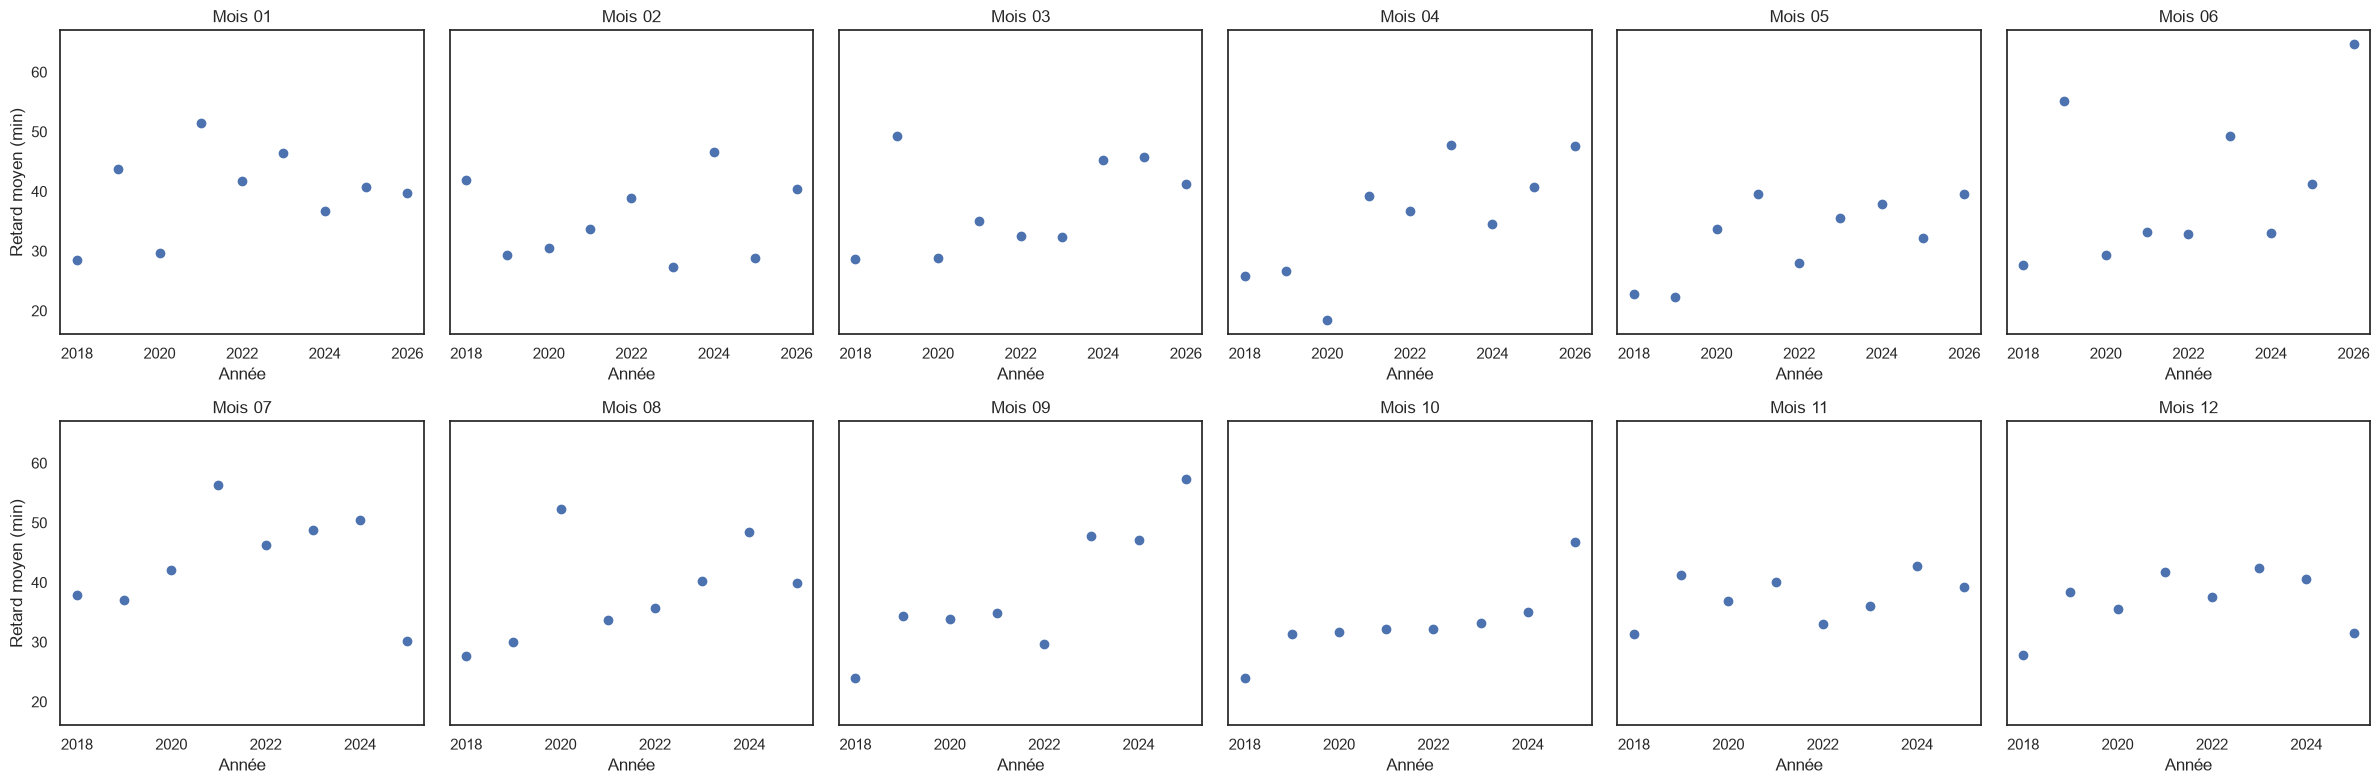

In [31]:
data_temp = df.droplevel(0, axis=1)

fig, axes = plt.subplots(2, 6, figsize=(24, 8), sharey=True)

for i, ax in zip(range(1, 13), axes.flat):
    data_mois = data_temp[(data_temp["Gare de départ"] == "BORDEAUX ST JEAN") & (data_temp["Gare d'arrivée"] == "PARIS MONTPARNASSE") & (data_temp["Saison"] == i)]
    ax.scatter(data_mois["Date"].dt.year, data_mois["Retard moyen des trains en retard à l'arrivée"])
    ax.set_title(f"Mois {i:02d}")
    ax.set_xlabel("Année")

axes[0, 0].set_ylabel("Retard moyen (min)")
axes[1, 0].set_ylabel("Retard moyen (min)")
plt.tight_layout()
plt.show()

**la même analyse par saison permet une meilleure extrapolation**

Bordeaux -> Paris

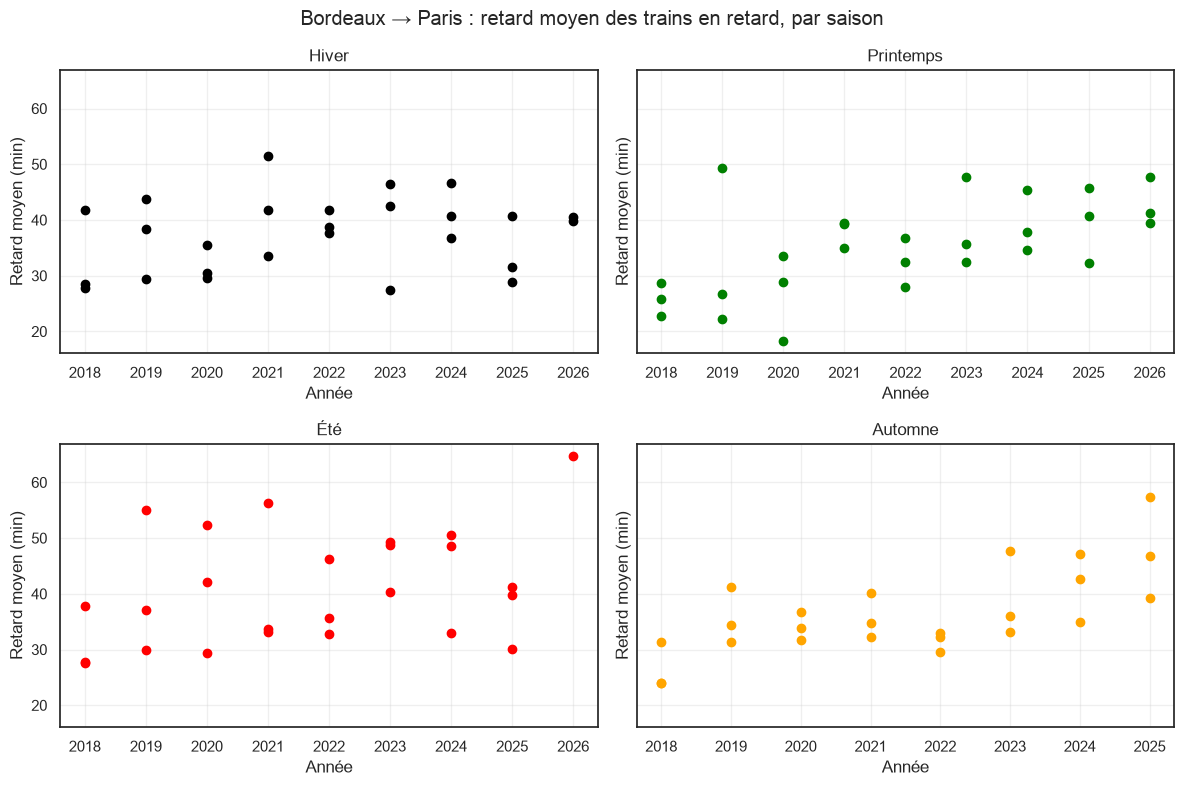

In [33]:
saisons = {
    "Hiver":     ([12, 1, 2],  "black"),
    "Printemps": ([3, 4, 5],   "green"),
    "Été":       ([6, 7, 8],   "red"),
    "Automne":   ([9, 10, 11], "orange"),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)

for ax, (nom, (mois, couleur)) in zip(axes.flat, saisons.items()):
    data_saison = data_temp[(data_temp["Gare de départ"] == "BORDEAUX ST JEAN") & (data_temp["Gare d'arrivée"] == "PARIS MONTPARNASSE") & (data_temp["Saison"].isin(mois))]
    ax.scatter(data_saison["Date"].dt.year,
               data_saison["Retard moyen des trains en retard à l'arrivée"],
               color=couleur)
    ax.set_title(nom)
    ax.set_xlabel("Année")
    ax.set_ylabel("Retard moyen (min)")
    ax.grid(True, alpha=0.3)

fig.suptitle("Bordeaux → Paris : retard moyen des trains en retard, par saison")
plt.tight_layout()
plt.show()

Autre trajet : Paris -> Lyon    **/!\ réaliser par IAG**

avec regression linéaire par saison

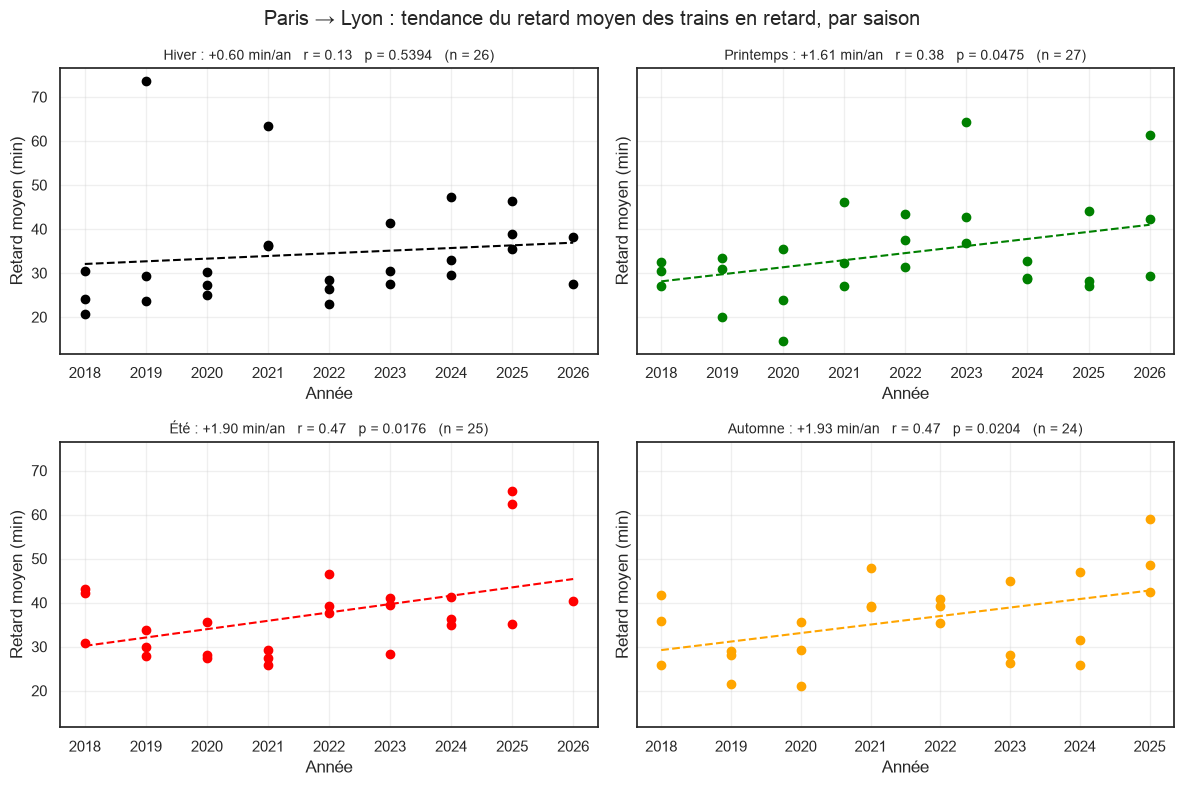

In [36]:
# GRAPHE PAR SAISON AVEC REGRESSION LINEAIRE
# TRAJET : PARIS -> LYON

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

data_temp = df.droplevel(0, axis=1)

COLONNE = "Retard moyen des trains en retard à l'arrivée"
saisons = {
    "Hiver":     ([12, 1, 2],  "black"),
    "Printemps": ([3, 4, 5],   "green"),
    "Été":       ([6, 7, 8],   "red"),
    "Automne":   ([9, 10, 11], "orange"),
}

trajet = data_temp[(data_temp["Gare de départ"] == "PARIS LYON") & (data_temp["Gare d'arrivée"] == "LYON PART DIEU")].copy()
trajet["Année"] = trajet["Date"].dt.year
trajet["Mois"] = trajet["Date"].dt.month

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)

for ax, (nom, (mois, couleur)) in zip(axes.flat, saisons.items()):
    s = trajet[trajet["Mois"].isin(mois)].dropna(subset=[COLONNE])
    x, y = s["Année"], s[COLONNE]

    reg = linregress(x, y)

    ax.scatter(x, y, color=couleur)
    xs = np.array([x.min(), x.max()])
    ax.plot(xs, reg.intercept + reg.slope * xs, color=couleur, linestyle="--")
    ax.set_title(f"{nom} : {reg.slope:+.2f} min/an   r = {reg.rvalue:.2f}   p = {reg.pvalue:.4f}   (n = {len(s)})",
                 fontsize=10)
    ax.set_xlabel("Année")
    ax.set_ylabel("Retard moyen (min)")
    ax.grid(True, alpha=0.3)

fig.suptitle("Paris → Lyon : tendance du retard moyen des trains en retard, par saison")
plt.tight_layout()
plt.show()

# Conclusion

Vu le manque de données, on remarque que le moindre outlier impact beaucoup la qualité de la regression linéaire (r se rapproche de 0 et p > 0.5 en hiver)

**choix non retenu** : supprimer l'outlier le plus important. Cependant ce choix impliquerait de ne pas prendre en compte les évènements rares provoquant des retards importants.

**choix non retenu** : donner un score de 60 min de retard à un train annulé rend la regression linéaire moins fiable :

### Paris → Lyon : régression linéaire du retard moyen par saison

| Saison    | Pente (sans annul.) | r (sans annul.) | p (sans annul.) | Pente (annul. = 60 min) | r (annul. = 60 min) | p (annul. = 60 min) | n  |
|-----------|---------------------|-----------------|-----------------|-------------------------|---------------------|---------------------|----|
| Hiver     | +0.60 min/an        | 0.13            | 0.5394          | +0.19 min/an            | 0.04                | 0.8353              | 26 |
| Printemps | +1.61 min/an        | 0.38            | **0.0475**      | -0.68 min/an            | -0.16               | 0.4383              | 27 |
| Été       | +1.90 min/an        | 0.47            | **0.0176**      | +1.24 min/an            | 0.31                | 0.1281              | 25 |
| Automne   | +1.93 min/an        | 0.47            | **0.0204**      | +1.31 min/an            | 0.34                | 0.1089              | 24 |

*En gras : p < 0.05 (tendance statistiquement significative).*